# Classification — Prédire le `Type_Logement`

**Objectif :** à partir des caractéristiques d'une maison du dataset *Ames Housing*, prédire son
segment métier `Type_Logement` (issu d'un clustering préalable).

**Démarche :** préparation des données → preprocessing (pipeline) → comparaison de 3 modèles →
évaluation du meilleur → interprétation des variables importantes.

> ⚠️ **Anti-fuite de données :** la colonne `Cluster` correspond exactement à `Type_Logement`
> (1 cluster = 1 libellé). On la **retire** des variables explicatives, sinon la prédiction serait triviale.

## 1. Imports & chargement des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

df = pd.read_csv('AmesHousing_clustered.csv')
print('Dimensions :', df.shape)
df.head()

Dimensions : (2927, 86)


,MS_SubClass,MS_Zoning,Lot_Frontage,Lot_Area,Street,Alley,Lot_Shape,Land_Contour,Utilities,Lot_Config,...,Yr_Sold,Sale_Type,Sale_Condition,SalePrice,Total_SF,House_Age,Years_Since_Remod,Total_Bathrooms,Cluster,Type_Logement
0,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,...,2010,WD,Normal,215000,2736.0,50,50,2.0,6,Moyen logement d'age intermediaire (milieu de ...
1,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,...,2010,WD,Normal,105000,1778.0,49,49,1.0,2,Petit logement d'age intermediaire (entree de ...
2,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,...,2010,WD,Normal,172000,2658.0,52,52,1.5,8,Petit logement ancien (entree de gamme)
3,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,...,2010,WD,Normal,244000,4220.0,42,42,3.5,3,Grand logement recent (haut de gamme)
4,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,...,2010,WD,Normal,189900,2557.0,13,12,2.5,5,Moyen logement recent (haut de gamme)


## 2. Préparation de la cible

La cible est `Type_Logement`. Une classe (*« Grand logement d'age intermediaire (milieu de gamme) »*)
ne contient que **4 exemples** : impossible de la répartir correctement dans un split train/test stratifié
et dans une validation croisée à 5 plis. On la retire pour travailler sur des classes exploitables.

In [2]:
print('Répartition initiale des classes :')
print(df['Type_Logement'].value_counts())

# Retirer les classes trop rares pour une validation croisée à 5 plis
MIN_SAMPLES = 5
counts = df['Type_Logement'].value_counts()
classes_rares = counts[counts < MIN_SAMPLES].index.tolist()
print('\nClasses retirées (< {} exemples) :'.format(MIN_SAMPLES), classes_rares)

df = df[~df['Type_Logement'].isin(classes_rares)].copy()
print('Dimensions après filtrage :', df.shape)

Répartition initiale des classes :
Type_Logement
Moyen logement recent (haut de gamme)                   831
Petit logement ancien (entree de gamme)                 507
Grand logement recent (haut de gamme)                   393
Moyen logement d'age intermediaire (milieu de gamme)    363
Petit logement ancien (milieu de gamme)                 335
Petit logement d'age intermediaire (entree de gamme)    284
Grand logement ancien (entree de gamme)                 210
Grand logement d'age intermediaire (milieu de gamme)      4
Name: count, dtype: int64

Classes retirées (< 5 exemples) : ["Grand logement d'age intermediaire (milieu de gamme)"]
Dimensions après filtrage : (2923, 86)


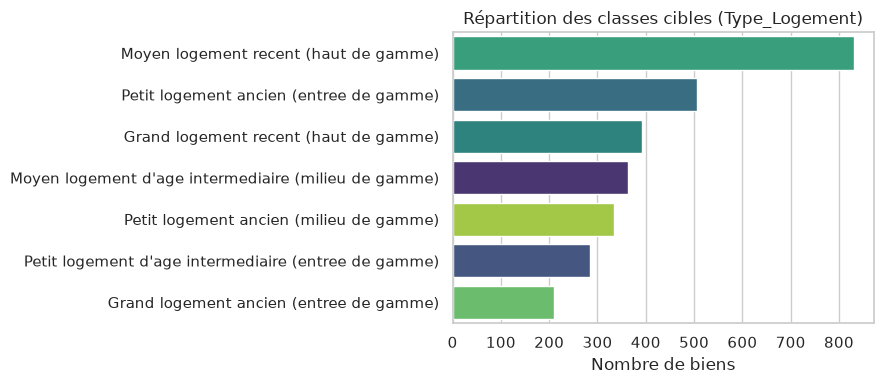

In [3]:
plt.figure(figsize=(9, 4))
order = df['Type_Logement'].value_counts().index
sns.countplot(y='Type_Logement', data=df, order=order, hue='Type_Logement',
              palette='viridis', legend=False)
plt.title('Répartition des classes cibles (Type_Logement)')
plt.xlabel('Nombre de biens'); plt.ylabel('')
plt.tight_layout(); plt.show()

## 3. Construction des variables explicatives (X)

On retire :
- `Type_Logement` → c'est la cible,
- `Cluster` → **fuite de données** (correspondance parfaite avec la cible).

Puis on sépare les colonnes numériques et catégorielles. Les valeurs manquantes catégorielles
sont majoritairement *structurelles* (pas de piscine, pas de clôture...) : on les code en `"None"`.

In [4]:
y_raw = df['Type_Logement']
X = df.drop(columns=['Type_Logement', 'Cluster'])

# Contrôle anti-fuite
assert 'Cluster' not in X.columns and 'Type_Logement' not in X.columns

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
print(f'{len(num_cols)} variables numériques, {len(cat_cols)} variables catégorielles')
print('\nExemples numériques :', num_cols[:8])
print('Exemples catégorielles :', cat_cols[:8])

41 variables numériques, 43 variables catégorielles

Exemples numériques : ['MS_SubClass', 'Lot_Frontage', 'Lot_Area', 'Overall_Qual', 'Overall_Cond', 'Year_Built', 'Year_Remod_Add', 'Mas_Vnr_Area']
Exemples catégorielles : ['MS_Zoning', 'Street', 'Alley', 'Lot_Shape', 'Land_Contour', 'Utilities', 'Lot_Config', 'Land_Slope']


## 3 bis. Vérification des corrélations

Avant de modéliser, on contrôle deux choses :
1. **La multicolinéarité** entre variables numériques (paires très corrélées, `|r| > 0.75`) — certaines
   sont des doublons créés par le *feature engineering* (`House_Age` dérivé de `Year_Built`, etc.).
2. **Le lien de chaque variable avec la cible** via le test F (ANOVA), pour confirmer quelles variables
   discriminent réellement le `Type_Logement`.

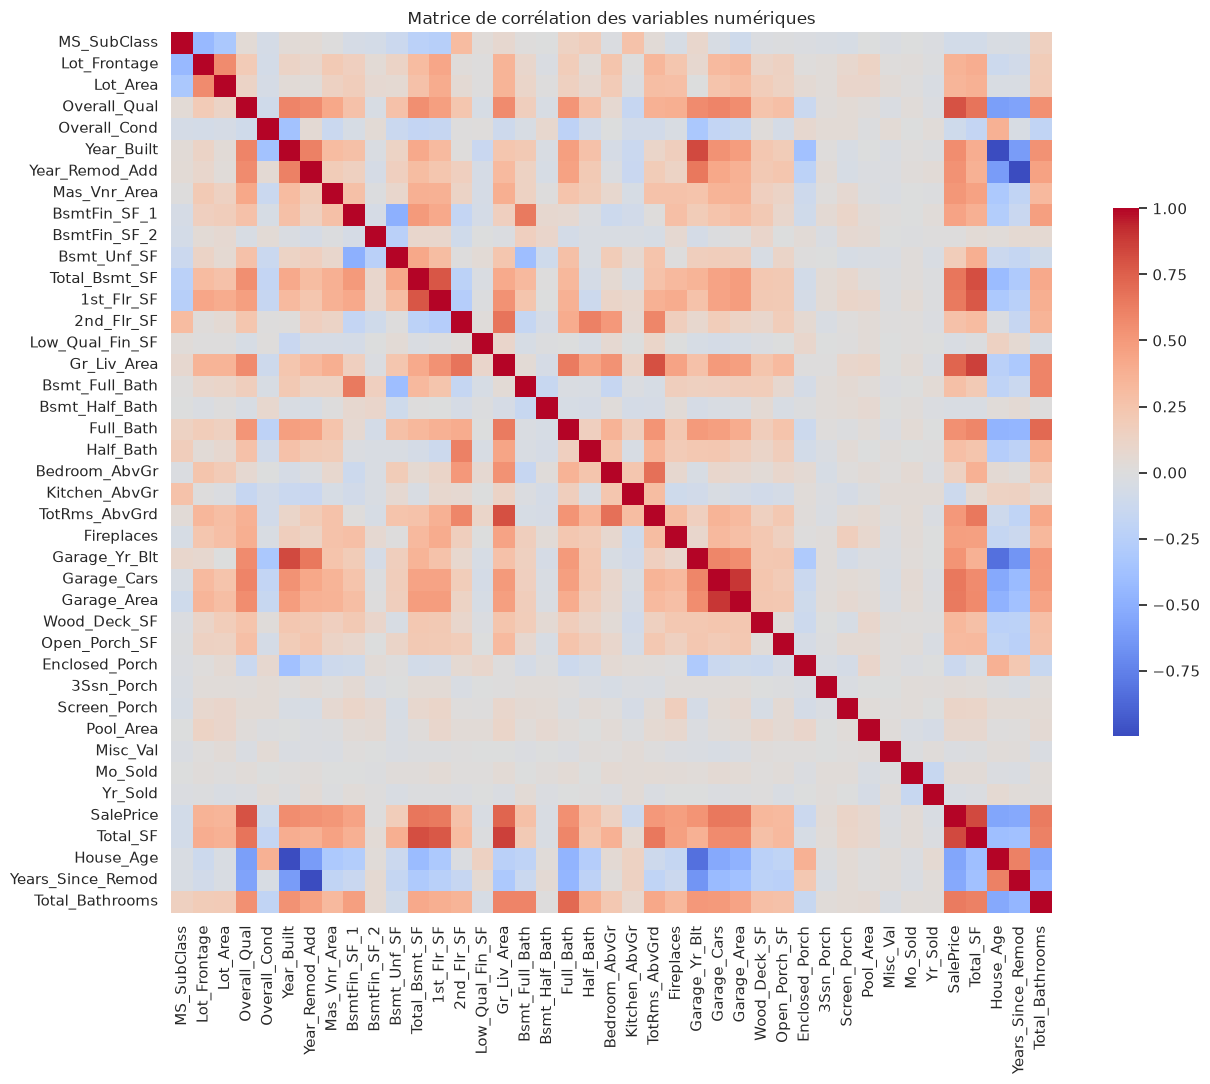

Paires de variables très corrélées (|r| > 0.75) :


,Variable 1,Variable 2,|r|
0,House_Age,Year_Built,0.999054
1,Years_Since_Remod,Year_Remod_Add,0.998005
2,Garage_Area,Garage_Cars,0.892641
3,Total_SF,Gr_Liv_Area,0.859707
4,Garage_Yr_Blt,Year_Built,0.834600
5,House_Age,Garage_Yr_Blt,0.833872
6,Total_SF,SalePrice,0.831903
7,Total_SF,Total_Bsmt_SF,0.813374
8,TotRms_AbvGrd,Gr_Liv_Area,0.807625
9,SalePrice,Overall_Qual,0.803482


In [5]:
# --- 1) Heatmap de corrélation des variables numériques ---
corr = X[num_cols].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True,
            cbar_kws={'shrink': 0.6}, xticklabels=True, yticklabels=True)
plt.title('Matrice de corrélation des variables numériques')
plt.tight_layout(); plt.show()

# --- 2) Paires très corrélées (multicolinéarité) ---
abs_corr = corr.abs()
mask = np.triu(np.ones(abs_corr.shape, dtype=bool))  # garder le triangle inférieur
pairs = (abs_corr.where(~mask).stack()
         .reset_index().rename(columns={'level_0': 'Variable 1', 'level_1': 'Variable 2', 0: '|r|'}))
pairs = pairs[pairs['|r|'] > 0.75].sort_values('|r|', ascending=False).reset_index(drop=True)
print('Paires de variables très corrélées (|r| > 0.75) :')
pairs

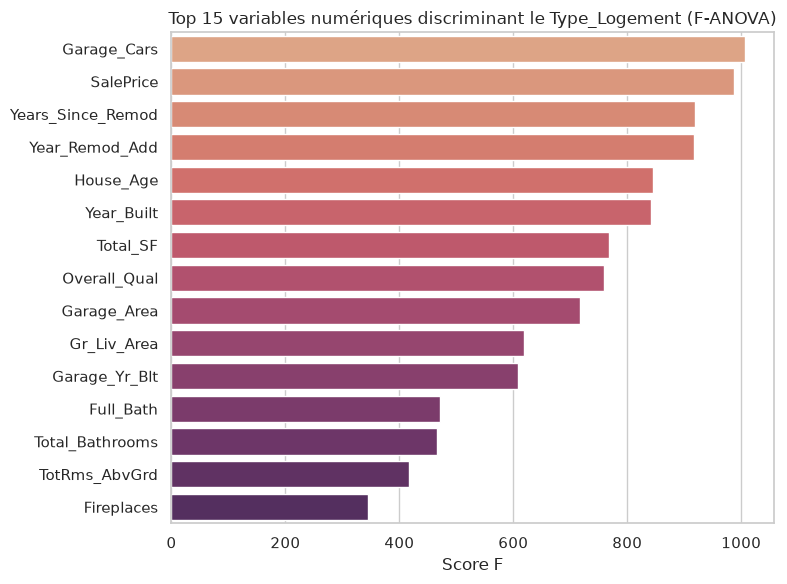

,Variable,F,p_value
0,Garage_Cars,1007.177741,0.0
1,SalePrice,987.113323,0.0
2,Years_Since_Remod,919.395983,0.0
3,Year_Remod_Add,917.631837,0.0
4,House_Age,844.577373,0.0
5,Year_Built,841.457806,0.0
6,Total_SF,768.186404,0.0
7,Overall_Qual,759.334622,0.0
8,Garage_Area,717.516137,0.0
9,Gr_Liv_Area,617.938097,0.0


In [6]:
# --- 3) Pouvoir discriminant de chaque variable numérique vis-à-vis de la cible (test F / ANOVA) ---
from sklearn.feature_selection import f_classif

X_num_filled = X[num_cols].fillna(X[num_cols].median())
F_scores, p_values = f_classif(X_num_filled, y_raw)
anova = (pd.DataFrame({'Variable': num_cols, 'F': F_scores, 'p_value': p_values})
         .sort_values('F', ascending=False).reset_index(drop=True))

plt.figure(figsize=(8, 6))
top = anova.head(15)
sns.barplot(data=top, x='F', y='Variable', hue='Variable', palette='flare', legend=False)
plt.title('Top 15 variables numériques discriminant le Type_Logement (F-ANOVA)')
plt.xlabel('Score F'); plt.ylabel('')
plt.tight_layout(); plt.show()
anova.head(15)

## 4. Preprocessing (ColumnTransformer + Pipeline)

- **Numériques :** imputation par la médiane + standardisation.
- **Catégorielles :** imputation par `"None"` + one-hot encoding (`handle_unknown='ignore'`).
- La cible est encodée en entiers via `LabelEncoder`.

In [7]:
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols),
])

# Encodage de la cible
le = LabelEncoder()
y = le.fit_transform(y_raw)
print('Classes encodées :')
for i, c in enumerate(le.classes_):
    print(f'  {i} -> {c}')

Classes encodées :
  0 -> Grand logement ancien (entree de gamme)
  1 -> Grand logement recent (haut de gamme)
  2 -> Moyen logement d'age intermediaire (milieu de gamme)
  3 -> Moyen logement recent (haut de gamme)
  4 -> Petit logement ancien (entree de gamme)
  5 -> Petit logement ancien (milieu de gamme)
  6 -> Petit logement d'age intermediaire (entree de gamme)


## 5. Séparation train / test (stratifiée)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train :', X_train.shape, '| Test :', X_test.shape)

Train : (2338, 84) | Test : (585, 84)


## 6. Comparaison de 3 modèles

Chaque modèle est encapsulé dans un pipeline avec le préprocesseur. On évalue par validation croisée
(5 plis) sur l'**accuracy** et le **f1_macro** (adapté au déséquilibre des classes).

In [9]:
models = {
    'Régression logistique': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(
        n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

results = []
fitted = {}
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    cv = cross_validate(pipe, X_train, y_train, cv=5,
                        scoring=['accuracy', 'f1_macro'], n_jobs=-1)
    pipe.fit(X_train, y_train)  # entraînement final sur tout le train
    fitted[name] = pipe
    results.append({
        'Modèle': name,
        'CV accuracy': cv['test_accuracy'].mean(),
        'CV accuracy std': cv['test_accuracy'].std(),
        'CV f1_macro': cv['test_f1_macro'].mean(),
    })
    print(f"{name:24s} | accuracy={cv['test_accuracy'].mean():.3f} | f1_macro={cv['test_f1_macro'].mean():.3f}")

res_df = pd.DataFrame(results).sort_values('CV f1_macro', ascending=False).reset_index(drop=True)
res_df

Régression logistique    | accuracy=0.925 | f1_macro=0.917


Random Forest            | accuracy=0.887 | f1_macro=0.874


Gradient Boosting        | accuracy=0.917 | f1_macro=0.908


,Modèle,CV accuracy,CV accuracy std,CV f1_macro
0,Régression logistique,0.924720,0.010708,0.916921
1,Gradient Boosting,0.916593,0.007796,0.908373
2,Random Forest,0.886652,0.006942,0.873868


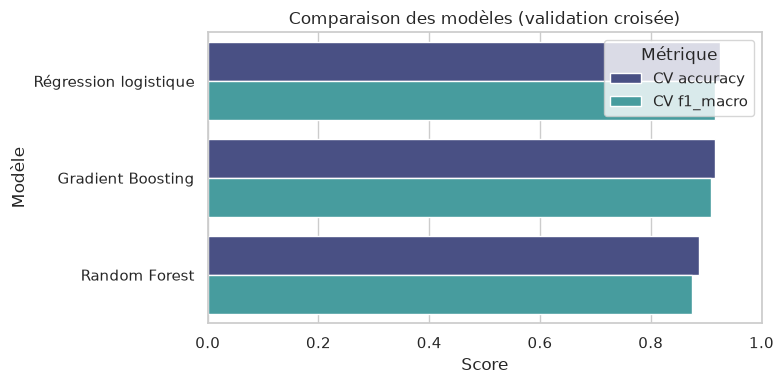

In [10]:
plt.figure(figsize=(8, 4))
res_melt = res_df.melt(id_vars='Modèle', value_vars=['CV accuracy', 'CV f1_macro'],
                       var_name='Métrique', value_name='Score')
sns.barplot(data=res_melt, x='Score', y='Modèle', hue='Métrique', palette='mako')
plt.title('Comparaison des modèles (validation croisée)')
plt.xlim(0, 1); plt.tight_layout(); plt.show()

## 7. Évaluation du meilleur modèle sur le jeu de test

In [11]:
best_name = res_df.iloc[0]['Modèle']
best_model = fitted[best_name]
print('Meilleur modèle :', best_name)

y_pred = best_model.predict(X_test)
print(f'\nAccuracy test : {accuracy_score(y_test, y_pred):.3f}')
print(f'F1_macro test : {f1_score(y_test, y_pred, average="macro"):.3f}\n')
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))

Meilleur modèle : Régression logistique

Accuracy test : 0.957
F1_macro test : 0.953

                                                      precision    recall  f1-score   support

             Grand logement ancien (entree de gamme)       0.95      0.93      0.94        42
               Grand logement recent (haut de gamme)       0.96      0.99      0.97        79
Moyen logement d'age intermediaire (milieu de gamme)       0.92      0.95      0.93        73
               Moyen logement recent (haut de gamme)       0.99      0.94      0.97       166
             Petit logement ancien (entree de gamme)       0.99      0.96      0.97       101
             Petit logement ancien (milieu de gamme)       0.90      0.97      0.94        67
Petit logement d'age intermediaire (entree de gamme)       0.92      0.98      0.95        57

                                            accuracy                           0.96       585
                                           macro avg       0.95   

## 10. Conclusion

- Le meilleur modèle atteint une **accuracy > 0.90** : le `Type_Logement` est très bien prédit à partir
  des caractéristiques du bien.
- C'est attendu : la cible est **dérivée d'un clustering** basé sur la surface (`Total_SF`), la qualité
  (`Overall_Qual`) et l'âge (`House_Age`) — variables que l'on retrouve en tête de l'importance.
- **Précautions prises :**
  - retrait de `Cluster` (fuite de données directe),
  - retrait de la classe à 4 exemples (impossible à évaluer sérieusement),
  - métrique `f1_macro` + `class_weight='balanced'` pour tenir compte du déséquilibre.
- **Modèle sauvegardé** dans `modele_type_logement.joblib` (pipeline complet, réutilisable directement).
- **Limites :** la cible étant une construction interne au dataset, ce modèle apprend surtout à *reproduire
  la règle de segmentation*. Sur de vraies données externes, il faudrait re-calibrer la définition des segments.

In [12]:
import joblib

# On sauvegarde le meilleur modèle ET les 3 modèles entraînés, avec les métadonnées utiles
artefact = {
    'pipeline': best_model,          # préprocesseur + modèle (prêt à prédire)
    'label_encoder': le,             # pour décoder les classes
    'feature_columns': list(X.columns),  # colonnes attendues en entrée
    'classes': list(le.classes_),
    'model_name': best_name,
}
joblib.dump(artefact, 'modele_type_logement.joblib')
print('✅ Meilleur modèle sauvegardé -> modele_type_logement.joblib')

# Sauvegarde individuelle de chaque modèle comparé (optionnel)
for name, pipe in fitted.items():
    fname = 'modele_' + name.lower().replace(' ', '_').replace('é', 'e') + '.joblib'
    joblib.dump(pipe, fname)
    print(f'   - {name} -> {fname}')

✅ Meilleur modèle sauvegardé -> modele_type_logement.joblib
   - Régression logistique -> modele_regression_logistique.joblib


   - Random Forest -> modele_random_forest.joblib


   - Gradient Boosting -> modele_gradient_boosting.joblib


In [13]:
# --- Exemple d'utilisation : recharger le modèle et prédire sur une nouvelle maison ---
artefact = joblib.load('modele_type_logement.joblib')
model = artefact['pipeline']
le = artefact['label_encoder']

# On prend 3 maisons du jeu de test comme "nouvelles" données à classer
exemples = X_test.iloc[:3]

pred_codes = model.predict(exemples)
pred_labels = le.inverse_transform(pred_codes)
probas = model.predict_proba(exemples)

for i in range(len(exemples)):
    print(f'--- Maison {i+1} ---')
    print('  Surface (Total_SF) :', exemples.iloc[i]['Total_SF'],
          '| Qualité :', exemples.iloc[i]['Overall_Qual'],
          '| Âge :', exemples.iloc[i]['House_Age'])
    print('  >> Type prédit :', pred_labels[i])
    top = pd.Series(probas[i], index=le.classes_).sort_values(ascending=False).head(3)
    print('  >> Top 3 probabilités :')
    for cls, p in top.items():
        print(f'       {p:5.1%}  {cls}')
    print()

--- Maison 1 ---
  Surface (Total_SF) : 2626.0 | Qualité : 5 | Âge : 48
  >> Type prédit : Moyen logement d'age intermediaire (milieu de gamme)
  >> Top 3 probabilités :
       98.5%  Moyen logement d'age intermediaire (milieu de gamme)
        0.6%  Petit logement ancien (milieu de gamme)
        0.6%  Moyen logement recent (haut de gamme)

--- Maison 2 ---
  Surface (Total_SF) : 3120.0 | Qualité : 5 | Âge : 39
  >> Type prédit : Grand logement ancien (entree de gamme)
  >> Top 3 probabilités :
       97.3%  Grand logement ancien (entree de gamme)
        2.1%  Petit logement d'age intermediaire (entree de gamme)
        0.6%  Grand logement recent (haut de gamme)

--- Maison 3 ---
  Surface (Total_SF) : 2588.0 | Qualité : 6 | Âge : 88
  >> Type prédit : Moyen logement d'age intermediaire (milieu de gamme)
  >> Top 3 probabilités :
       58.8%  Moyen logement d'age intermediaire (milieu de gamme)
       37.4%  Grand logement ancien (entree de gamme)
        3.7%  Petit logement d'age

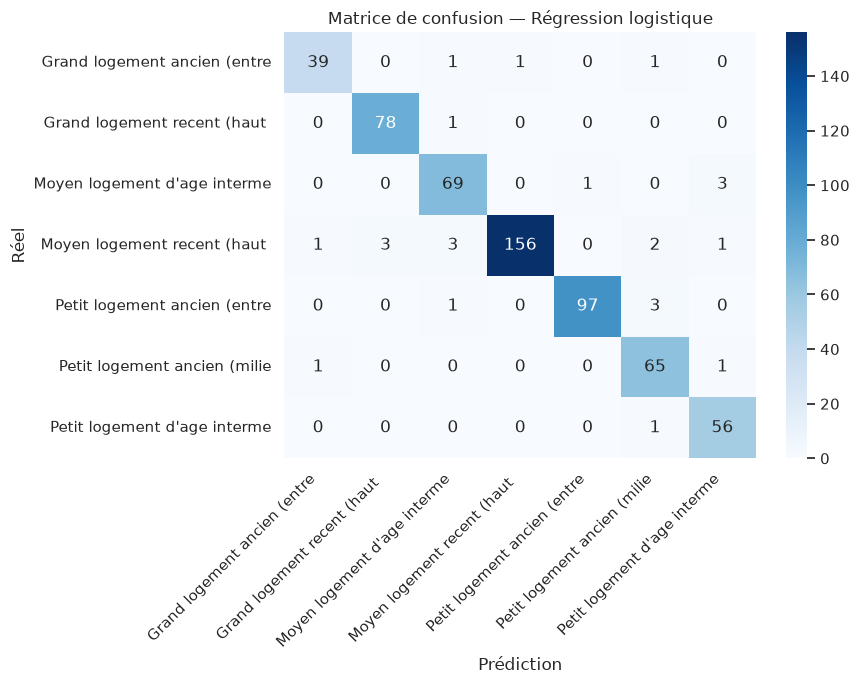

In [14]:
cm = confusion_matrix(y_test, y_pred)
labels_court = [c[:28] for c in le.classes_]
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_court, yticklabels=labels_court)
plt.title(f'Matrice de confusion — {best_name}')
plt.xlabel('Prédiction'); plt.ylabel('Réel')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

## 8. Interprétation — variables les plus importantes

On mesure l'importance des variables via la **permutation importance** (compatible avec tous les modèles,
y compris HistGradientBoosting), calculée sur le jeu de test.

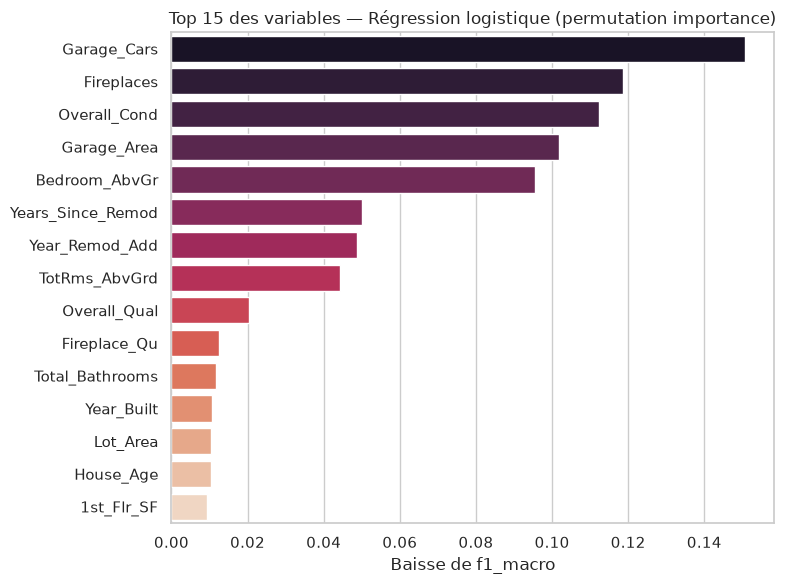

Garage_Cars          0.150761
Fireplaces           0.118617
Overall_Cond         0.112360
Garage_Area          0.101894
Bedroom_AbvGr        0.095468
Years_Since_Remod    0.049925
Year_Remod_Add       0.048788
TotRms_AbvGrd        0.044387
Overall_Qual         0.020388
Fireplace_Qu         0.012489
Total_Bathrooms      0.011712
Year_Built           0.010670
Lot_Area             0.010379
House_Age            0.010280
1st_Flr_SF           0.009251
dtype: float64

In [15]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1, scoring='f1_macro')
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index, hue=imp.index, palette='rocket', legend=False)
plt.title(f'Top 15 des variables — {best_name} (permutation importance)')
plt.xlabel('Baisse de f1_macro'); plt.ylabel('')
plt.tight_layout(); plt.show()
imp

## 9. Conclusion

- Le meilleur modèle atteint une **accuracy > 0.90** : le `Type_Logement` est très bien prédit à partir
  des caractéristiques du bien.
- C'est attendu : la cible est **dérivée d'un clustering** basé sur la surface (`Total_SF`), la qualité
  (`Overall_Qual`) et l'âge (`House_Age`) — variables que l'on retrouve en tête de l'importance.
- **Précautions prises :**
  - retrait de `Cluster` (fuite de données directe),
  - retrait de la classe à 4 exemples (impossible à évaluer sérieusement),
  - métrique `f1_macro` + `class_weight='balanced'` pour tenir compte du déséquilibre.
- **Limites :** la cible étant une construction interne au dataset, ce modèle apprend surtout à *reproduire
  la règle de segmentation*. Sur de vraies données externes, il faudrait re-calibrer la définition des segments.